## **Workshop**
### Tutorial: Getting Started with NEMO Cookbook

#### 18th November 2026

#### **Contact:**
Ollie Tooth (oliver.tooth@noc.ac.uk), National Oceanography Centre

#### **Background:**
---


NEMO Cookbook extends the familiar xarray data model with grid-aware data structures designed for performing reproducible analyses of the Nucleus for European Modelling of the Ocean ([**NEMO**](https://www.nemo-ocean.eu/)) ocean general circulation model outputs.

In these hands-on tutorials, we will use the `NEMODataTree` object to analyse ocean & sea-ice outputs of the AGRIF-DEMO reference configuration, UKESM1-0-LL CMIP6 coupled climate model, and National Oceanography Centre Near-Present Day hindcast simulations.

We will cover:

* Creating `NEMODataTree` objects directly from local NetCDF files, cloud-based CMORISED outputs from coupled climate models, and from version-controlled Icechunk repositories accessed through [**OceanDataStore**](https://noc-msm.github.io/OceanDataStore/).

* Exploring NEMO ocean & sea-ice variables stored in a `NEMODataTree`.

* Geographical plotting of `NEMODataArray`.

* Performing grid-aware operations using `NEMODataArray`.

* Extracting hydrographic sections using `extract_zonal_section()`.

#### **1.1 Creating NEMODataTrees**
---

* Let's begin by importing the **NEMO Cookbook** Python library and the `NEMODataTree` class:

In [1]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

import nemo_cookbook as ncb
from nemo_cookbook import NEMODataTree
from OceanDataStore import OceanDataCatalog

##### **1.1.1 Creating a NEMODataTree from Local Files**

* We'll begin by creating a simple `NEMODataTree` using local NEMO model output files from the `AGRIF_DEMO` reference configuration.

---

`AGRIF_DEMO`

* `AGRIF_DEMO` is based on the `ORCA2_ICE_PISCES` global reference configuration with the inclusion of 3 online nested domains.

* Here, we will only consider the 2° global parent domain.

* **NEMO Cookbook** includes a subset of the `AGRIF_DEMO` model outputs made accessible via cloud object storage.

* Further information on this reference configuration can be found [**here**](https://sites.nemo-ocean.io/user-guide/cfgs.html#agrif-demo).

---

* Let's download and collect the filepaths for the `AGRIF_DEMO` configuration using the `nemo_cookbook.examples.get_filepaths()` convenience function, which caches and generates local filepaths for available NEMO reference configurations:

In [2]:
filepaths = ncb.examples.get_filepaths("AGRIF_DEMO")
filepaths

{'domain_cfg.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/domain_cfg.nc',
 '2_domain_cfg.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/2_domain_cfg.nc',
 '3_domain_cfg.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/3_domain_cfg.nc',
 'ORCA2_5d_00010101_00010110_grid_T.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/ORCA2_5d_00010101_00010110_grid_T.nc',
 'ORCA2_5d_00010101_00010110_grid_U.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/ORCA2_5d_00010101_00010110_grid_U.nc',
 'ORCA2_5d_00010101_00010110_grid_V.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/ORCA2_5d_00010101_00010110_grid_V.nc',
 'ORCA2_5d_00010101_00010110_grid_W.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/ORCA2_5d_00010101_00010110_grid_W.nc',
 'ORCA2_5d_00010101_00010110_icemod.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/ORCA2_5d_00010101_00010110_icemod.nc',
 '2_Nordic_5d_00010101_00010110_grid_T.nc': '/home/otooth/.cache/nemo_cookbook/AGRIF_DEMO/2_Nordic_5d_00010101_00010110_gr

* We can create a `NEMODataTree` from a dictionary of paths to local netCDF files using the `.from_paths()` constructor:

---

`from_paths()`

* Creates a `NEMODataTree` from a dictionary of paths to NEMO model outputs files organised into a hierarchy (e.g., `parent`, `child` `grandchild`) of NEMO model grids (e.g., `gridT`, `gridU`, etc.):
```
    <xarray.DataTree 'nemo'>
    Group: /
    ├── Group: /gridT
    ├── Group: /gridU
    ├── Group: /gridV
    ├── Group: /gridW
    └── Group: /gridF
```

where the `gridT` node contains time series of scalar variables stored in the `...grid_T.nc` files in a single `xarray.Dataset` and so on.

---

* Let's start by defining the `paths` dictionary, which contains the filepaths corresponding to our global parent domain.

* We populate the `parent` dictionary with the filepaths to the `domain_cfg` and `gridT/U/V/W` netCDF files produced for the `AGRIF_DEMO` (ORCA2) parent domain. 

In [3]:
paths = {"parent": {"domain": filepaths["domain_cfg.nc"],
                    "gridT": filepaths["ORCA2_5d_00010101_00010110_grid_T.nc"],
                    "gridU": filepaths["ORCA2_5d_00010101_00010110_grid_U.nc"],
                    "gridV": filepaths["ORCA2_5d_00010101_00010110_grid_V.nc"],
                    "gridW": filepaths["ORCA2_5d_00010101_00010110_grid_W.nc"],
                    "icemod": filepaths["ORCA2_5d_00010101_00010110_icemod.nc"]
                    },
         }

* We can now construct a new `NEMODataTree` using the `.from_paths()` constructor.

* **Note that we also need to specify that our global parent domain is zonally periodic (`iperio=True`) and north folding on T-points (`nftype = "T"`) rather than a closed (regional) domain.**

In [4]:
NEMODataTree.from_paths(paths, iperio=True, nftype="T", chunks={})

<xarray.DataTree 'NEMO model'>
Group: /
│   Dimensions:               (time_counter: 2, axis_nbounds: 2, ncatice: 5)
│   Coordinates:
│     * time_counter          (time_counter) object 16B 0001-01-03 12:00:00 0001-...
│       time_centered         (time_counter) object 16B dask.array<chunksize=(1,), meta=np.ndarray>
│       time_instant          (time_counter) object 16B dask.array<chunksize=(1,), meta=np.ndarray>
│     * ncatice               (ncatice) float32 20B 1.0 2.0 3.0 4.0 5.0
│   Dimensions without coordinates: axis_nbounds
│   Data variables:
│       time_centered_bounds  (time_counter, axis_nbounds) object 32B dask.array<chunksize=(1, 2), meta=np.ndarray>
│       time_counter_bounds   (time_counter, axis_nbounds) object 32B dask.array<chunksize=(1, 2), meta=np.ndarray>
│       time_instant_bounds   (time_counter, axis_nbounds) object 32B dask.array<chunksize=(1, 2), meta=np.ndarray>
│   Attributes:
│       nftype:   T
│       iperio:   True
├── Group: /gridT
│       Dimensions:               (k: 31, axis_nbounds: 2, time_counter: 2, j: 148,
│                                  i: 180, ncatice: 5)
│       Coordinates:
│         * k                     (k) int64 248B 1 2 3 4 5 6 7 ... 25 26 27 28 29 30 31
│         * deptht                (k) float32 124B 5.0 15.0 25.0 ... 4.75e+03 5.25e+03
│           time_centered         (time_counter) object 16B dask.array<chunksize=(1,), meta=np.ndarray>
│           time_instant          (time_counter) object 16B dask.array<chunksize=(1,), meta=np.ndarray>
│         * j                     (j) int64 1kB 1 2 3 4 5 6 ... 143 144 145 146 147 148
│         * i                     (i) int64 1kB 1 2 3 4 5 6 ... 175 176 177 178 179 180
│           gphit                 (j, i) float64 213kB ...
│           glamt                 (j, i) float64 213kB ...
│       Dimensions without coordinates: axis_nbounds
│       Data variables: (12/85)
│           deptht_bounds         (k, axis_nbounds) float32 248B dask.array<chunksize=(31, 2), meta=np.ndarray>
│           time_centered_bounds  (time_counter, axis_nbounds) object 32B dask.array<chunksize=(1, 2), meta=np.ndarray>
│           time_counter_bounds   (time_counter, axis_nbounds) object 32B dask.array<chunksize=(1, 2), meta=np.ndarray>
│           time_instant_bounds   (time_counter, axis_nbounds) object 32B dask.array<chunksize=(1, 2), meta=np.ndarray>
│           e3t                   (time_counter, k, j, i) float32 7MB dask.array<chunksize=(1, 31, 148, 180), meta=np.ndarray>
│           thetao                (time_counter, k, j, i) float32 7MB dask.array<chunksize=(1, 31, 148, 180), meta=np.ndarray>
│           ...                    ...
│           sisalcat              (time_counter, ncatice, j, i) float32 1MB dask.array<chunksize=(1, 5, 148, 180), meta=np.ndarray>
│           sitemcat              (time_counter, ncatice, j, i) float32 1MB dask.array<chunksize=(1, 5, 148, 180), meta=np.ndarray>
│           tmask                 (k, j, i) bool 826kB False False False ... False False
│           tmaskutil             (j, i) bool 27kB False False False ... False False
│           e1t                   (j, i) float64 213kB ...
│           e2t                   (j, i) float64 213kB ...
│       Attributes:
│           name:         ORCA2_5d_00010101_00010110_grid_T
│           description:  ocean T grid variables
│           title:        ocean T grid variables
│           Conventions:  CF-1.6
│           timeStamp:    2025-Sep-13 17:44:13 GMT
│           uuid:         92bd7786-afa1-44db-8a63-995c0e56d322
├── Group: /gridU
│       Dimensions:               (k: 31, axis_nbounds: 2, time_counter: 2, j: 148,
│                                  i: 180)
│       Coordinates:
│         * k                     (k) int64 248B 1 2 3 4 5 6 7 ... 25 26 27 28 29 30 31
│         * depthu                (k) float32 124B 5.0 15.0 25.0 ... 4.75e+03 5.25e+03
│           time_centered         (time_counter) object 16B dask.array<chunksize=(1,), meta=np.ndarray>
│ 

##### **1.1.2 Creating a NEMODataTree from CMORISED Datasets**

* In addition to reading netCDF files directly, we can also create a `NEMODataTree` from a dictionary of `xarray.Datasets` using the `.from_datasets()` constructor:

---

`from_datasets()`

* Creates a `NEMODataTree` from a dictionary of `xarray.Datasets` organised into a hierarchy (e.g., `parent`, `child` `grandchild`) of NEMO model grids (e.g., `gridT`, `gridU`, etc.):

```
    <xarray.DataTree 'nemo'>
    Group: /
    ├── Group: /gridT
    ├── Group: /gridU
    ├── Group: /gridV
    ├── Group: /gridW
    └── Group: /gridF
```

where the `gridT` node contains time series of scalar variables stored in the input `xarray.Dataset` and so on.

---

* Here, we show how to construct a `NEMODataTree` from the 1° global ocean sea-ice component of **UKESM1-0-LL** using outputs accessible via the [AWS Open Data Registry](https://registry.opendata.aws/cmip6/).

* Since CMIP6 outputs are processed and formatted according to the CMIP Community Climate Model Output Rewriter (CMOR) software, we will need to include a few additional pre-processing steps to reformat our NEMO model outputs in order to construct a `NEMODataTree`

**Important: only CMIP model outputs variables stored on their original NEMO ocean model grid (i.e, `gn`) can be used to construct a `NEMODataTree`**

In [5]:
# Define path to UKESM1 domain_cfg Zarr store:
domain_url = "https://noc-msm-o.s3-ext.jc.rl.ac.uk/nemo-cookbook/ukesm1/domain_cfg"

# Open eORCA1 NEMO model domain_cfg:
ds_domain = xr.open_zarr(domain_url, consolidated=True, chunks={})

ds_domain

<xarray.Dataset> Size: 488MB
Dimensions:       (y: 330, x: 360, nav_lev: 75)
Dimensions without coordinates: y, x, nav_lev
Data variables: (12/47)
    bathy         (y, x) float32 475kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    e1f           (y, x) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    e1t           (y, x) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    e1u           (y, x) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    e1v           (y, x) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    e2f           (y, x) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    ...            ...
    umask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(25, 330, 360), meta=np.ndarray>
    umaskutil     (y, x) int8 119kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    vmask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(25, 330, 360), meta=np.ndarray>
    vmaskutil     (y, x) int8 119kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    wmask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(25, 330, 360), meta=np.ndarray>
    wmaskutil     (y, x) int8 119kB dask.array<chunksize=(330, 360), meta=np.ndarray>
Attributes:
    file_name:  mesh_mask.nc
    TimeStamp:  06/02/2026 10:14:02 +0000

In [6]:
# -- Create NEMO gridT dataset from UKESM1-2-LL -- #
# Define base URL and storage options to access CMIP6 data from S3:
base_url = "s3://cmip6-pds/CMIP6/CMIP/MOHC/UKESM1-0-LL/esm-hist/r1i1p1f2/Omon"
storage_options = {"anon": True}

# Open conservative temperature (deg C), vertical grid cell thicknesses (m), and sea surface height (m) variables from Zarr v2 stores:
ds_thetao = xr.open_zarr(f"{base_url}/thetao/gn/v20190723", storage_options=storage_options, zarr_format=2)
ds_thkcello = xr.open_zarr(f"{base_url}/thkcello/gn/v20190723", storage_options=storage_options, zarr_format=2)
ds_zos = xr.open_zarr(f"{base_url}/zos/gn/v20190723", storage_options=storage_options, zarr_format=2)

# Construct single NEMO model T-grid dataset:
ds_gridT = xr.merge([ds_thetao, ds_thkcello, ds_zos], compat="override", join='override')

# Update dimension names and rename thkcello -> e3t:
ds_gridT = ds_gridT.rename({"time": "time_counter",
                            "lev": "deptht",
                            "j": "y",
                            "i": "x",
                            "thkcello": "e3t"
                            })
ds_gridT

<xarray.Dataset> Size: 142GB
Dimensions:             (time_counter: 1980, deptht: 75, y: 330, x: 360,
                         vertices: 4, bnds: 2)
Coordinates:
  * time_counter        (time_counter) object 16kB 1850-01-16 00:00:00 ... 20...
  * deptht              (deptht) float64 600B 0.5058 1.556 ... 5.902e+03
  * y                   (y) int32 1kB 0 1 2 3 4 5 6 ... 324 325 326 327 328 329
  * x                   (x) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (y, x) float32 475kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    longitude           (y, x) float32 475kB dask.array<chunksize=(330, 360), meta=np.ndarray>
    lev_bnds            (deptht, bnds) float64 1kB dask.array<chunksize=(75, 2), meta=np.ndarray>
    time_bnds           (time_counter, bnds) object 32kB dask.array<chunksize=(1980, 2), meta=np.ndarray>
Dimensions without coordinates: vertices, bnds
Data variables:
    thetao              (time_counter, deptht, y, x) float32 71GB dask.array<chunksize=(4, 75, 330, 360), meta=np.ndarray>
    vertices_latitude   (y, x, vertices) float32 2MB dask.array<chunksize=(330, 360, 4), meta=np.ndarray>
    vertices_longitude  (y, x, vertices) float32 2MB dask.array<chunksize=(330, 360, 4), meta=np.ndarray>
    e3t                 (time_counter, deptht, y, x) float32 71GB dask.array<chunksize=(6, 75, 330, 360), meta=np.ndarray>
    zos                 (time_counter, y, x) float32 941MB dask.array<chunksize=(242, 330, 360), meta=np.ndarray>
Attributes: (12/47)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.4.0
    ...                     ...
    table_id:               Omon
    table_info:             Creation Date:(13 December 2018) MD5:2b12b5db6db1...
    title:                  UKESM1-0-LL output prepared for CMIP6
    tracking_id:            hdl:21.14100/262570a1-6ce8-4a2f-b673-054cae1cd25f...
    variable_id:            thetao
    variant_label:          r1i1p1f2

Now we have defined our `domain` and `gridT` datasets, let's define a `datasets` dictionary ensuring that we rename CMORISED dimensions to be consistent with standard NEMO model outputs.

**Note that we must rename the CMORISED variable `thkcello` to standard NEMO name `e3t`**

We can then define a `NEMODataTree` using the `.from_datasets()` constructor, specifying that our global parent domain is zonally periodic and north-folding on F-points.

**Note that we will still obtain a `NEMODataTree` with a complete set of grid nodes (i.e., `gridT`, `gridU`, etc.)**

In [7]:
datasets = {"parent": {"domain": ds_domain, "gridT": ds_gridT}}

NEMODataTree.from_datasets(datasets=datasets, iperio=True, nftype="F", read_mask=True, vco_ref=True, name="UKESM1-0-LL")

<xarray.DataTree 'UKESM1-0-LL'>
Group: /
│   Dimensions:       (time_counter: 1980, bnds: 2)
│   Coordinates:
│     * time_counter  (time_counter) object 16kB 1850-01-16 00:00:00 ... 2014-12-...
│       time_bnds     (time_counter, bnds) object 32kB dask.array<chunksize=(1980, 2), meta=np.ndarray>
│   Dimensions without coordinates: bnds
│   Attributes:
│       nftype:   F
│       iperio:   True
├── Group: /gridT
│       Dimensions:             (time_counter: 1980, k: 75, j: 330, i: 360,
│                                vertices: 4, bnds: 2)
│       Coordinates:
│         * k                   (k) int64 600B 1 2 3 4 5 6 7 8 ... 69 70 71 72 73 74 75
│         * deptht              (k) float64 600B 0.5058 1.556 ... 5.698e+03 5.902e+03
│         * j                   (j) int64 3kB 1 2 3 4 5 6 7 ... 325 326 327 328 329 330
│         * i                   (i) int64 3kB 1 2 3 4 5 6 7 ... 355 356 357 358 359 360
│           latitude            (j, i) float32 475kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│           longitude           (j, i) float32 475kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│           gphit               (j, i) float32 475kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│           glamt               (j, i) float32 475kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│           lev_bnds            (k, bnds) float64 1kB dask.array<chunksize=(75, 2), meta=np.ndarray>
│           time_bnds           (time_counter, bnds) object 32kB dask.array<chunksize=(1980, 2), meta=np.ndarray>
│       Dimensions without coordinates: vertices, bnds
│       Data variables:
│           thetao              (time_counter, k, j, i) float32 71GB dask.array<chunksize=(4, 75, 330, 360), meta=np.ndarray>
│           vertices_latitude   (j, i, vertices) float32 2MB dask.array<chunksize=(330, 360, 4), meta=np.ndarray>
│           vertices_longitude  (j, i, vertices) float32 2MB dask.array<chunksize=(330, 360, 4), meta=np.ndarray>
│           e3t                 (time_counter, k, j, i) float32 71GB dask.array<chunksize=(6, 75, 330, 360), meta=np.ndarray>
│           zos                 (time_counter, j, i) float32 941MB dask.array<chunksize=(242, 330, 360), meta=np.ndarray>
│           tmask               (k, j, i) int8 9MB dask.array<chunksize=(25, 330, 360), meta=np.ndarray>
│           tmaskutil           (j, i) int8 119kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│           e1t                 (j, i) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│           e2t                 (j, i) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│           e3t_0               (k, j, i) float64 71MB dask.array<chunksize=(25, 330, 360), meta=np.ndarray>
│           ht_0                (j, i) float64 950kB dask.array<chunksize=(330, 360), meta=np.ndarray>
│       Attributes: (12/47)
│           Conventions:            CF-1.7 CMIP-6.2
│           activity_id:            CMIP
│           branch_method:          standard
│           branch_time_in_child:   0.0
│           branch_time_in_parent:  0.0
│           cmor_version:           3.4.0
│           ...                     ...
│           table_id:               Omon
│           table_info:             Creation Date:(13 December 2018) MD5:2b12b5db6db1...
│           title:                  UKESM1-0-LL output prepared for CMIP6
│           tracking_id:            hdl:21.14100/262570a1-6ce8-4a2f-b673-054cae1cd25f...
│           variable_id:            thetao
│           variant_label:          r1i1p1f2
├── Group: /gridU
│       Dimensions:       (k: 75, j: 330, i: 360)
│       Coordinates:
│         * k             (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
│         * depthu        (k) float64 600B 0.5058 1.556 2.668 ... 5.698e+03 5.902e+03
│         * j             (j) int64 3kB 1 2 3 4 5 6 7 8 ... 324 325 326 327 328 329 330
│         * i             (i) float64 3kB 1.5 2.5 3.5 4.5 ... 357.5 358.5 359.5 360.5
│    

##### **1.1.3 Opening a Serialised NEMODataTree**

* Rather that having to merge *O*(100) - *O*(1000s) of NetCDF files to create a `NEMODataTree` at the begining of every script, we can instead serialise a `NEMODataTree` to a hierarchical NetCDF file, Zarr store or version-controlled Icechunk repository.

* To access a `NEMODataTree` stored in an Icechunk repository in cloud object storage, we can use the `.from_icechunk()` constructor:

---

`from_icechunk()`

* Creates a `NEMODataTree` from an Icechunk repository:

```
    <xarray.DataTree 'nemo'>
    Group: /
    ├── Group: /gridT
    ├── Group: /gridU
    ├── Group: /gridV
    ├── Group: /gridW
    └── Group: /gridF
```

where each grid node is stored in separate groups of a hierarchical Icechunk store.

---

* Here, we show how to use NOC's OceanDataStore to access a `NEMODataTree` which has been serialised into a version-controlled Icechunk repository.

* We'll access the NOC Near-Present-Day eORCA1 monthly-mean `NEMODataTree` forced using a bias-corrected ERA5v1 atmospheric reanalysis.

In [8]:
# Create an instance of the OceanDataCatalog with the OceanDataStore STAC:
catalog = OceanDataCatalog(catalog_name="ods-stac")

# Return a metadata summary of the NOC NPD eORCA1 monthly-mean datacube:
catalog.item_summary(id="noc-npd-era5/npd-eorca1-era5v1/r1i1c1f1/eorca1-era5v1-1m")

Title,Description
NPD eORCA1 ERA5v1 1m NEMODataTree,Monthly-mean global ocean outputs.
Property,Value
dataset_type,model
product_type,timeseries
product_version,1.0
institution,"National Oceanography Centre, UK"
citation,"Blaker, A. T., Tooth, O. J., Palmiéri, J., Coward, A. C., and Mecking, J. (2025). NOC-MSM/NOC_Near_Present_Day: v0.9.0 (v0.9.0). Zenodo. https://doi.org/10.5281/zenodo.15310354."
acknowledgement,NOC Near-Present Day Documentation available at: https://noc-msm.github.io/NOC_Near_Present_Day/
license,UK Open Government License v3.0
doi,pending


In [9]:
# Open the Icechunk repository directly from the catalog:
repo = catalog.open_repo(id="noc-npd-era5/npd-eorca1-era5v1/r1i1c1f1/eorca1-era5v1-1m")

# Open the NEMODataTree from the Icechunk repository:
nemo = NEMODataTree.from_icechunk(repo=repo,
                                  branch="main",
                                  iperio=True,
                                  nftype="F",
                                  )

nemo

<xarray.DataTree 'NEMO model'>
Group: /
│   Attributes: (12/31)
│       Conventions:                 CF-1.6
│       title:                       National Oceanography Centre Near-Present Da...
│       description:                 NOC Near-Present Day monthly mean global oce...
│       dataset_type:                model
│       product_type:                timeseries
│       product_version:             1.0
│       ...                          ...
│       biogeochemistry_component:   None
│       atmospheric_component:       None
│       atmospheric_forcing:         ERA5 v1
│       variant:                     r1i1c1f1
│       nftype:                      F
│       iperio:                      True
├── Group: /gridF
│       Dimensions:    (j: 331, i: 360, k: 75)
│       Coordinates:
│         * j          (j) float64 3kB 1.5 2.5 3.5 4.5 5.5 ... 328.5 329.5 330.5 331.5
│         * i          (i) float64 3kB 1.5 2.5 3.5 4.5 5.5 ... 357.5 358.5 359.5 360.5
│           glamf      (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           gphif      (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│         * k          (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 67 68 69 70 71 72 73 74 75
│       Data variables:
│           e1f        (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           fmaskutil  (j, i) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           fmask      (k, j, i) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
│           e2f        (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│       Attributes: (12/29)
│           Conventions:                 CF-1.6
│           title:                       National Oceanography Centre Near-Present Da...
│           description:                 NOC Near-Present Day monthly mean global oce...
│           dataset_type:                model
│           product_type:                timeseries
│           product_version:             1.0
│           ...                          ...
│           ocean_component:             NEMO v4.2.2
│           sea_ice_component:           SI3 v4.0
│           biogeochemistry_component:   None
│           atmospheric_component:       None
│           atmospheric_forcing:         ERA5 v1
│           variant:                     r1i1c1f1
├── Group: /gridU
│       Dimensions:        (j: 331, i: 360, time_counter: 604, k: 75)
│       Coordinates:
│         * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
│         * i              (i) float64 3kB 1.5 2.5 3.5 4.5 ... 357.5 358.5 359.5 360.5
│           gphiu          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           glamu          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│         * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
│           time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
│         * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
│           depthu         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
│       Data variables:
│           e1u            (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           hfx            (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           e2u            (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           e3u            (time_counter, k, j, i) float32 22GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
│           sozosatr       (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           umaskutil      (j, i) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           umo            (time_counter, k, j, i) float32 22GB dask.array<chunksize=(1, 25, 331, 360), 

#### **1.2 Navigating a NEMODataTree**
---

* Now we have created an example `NEMODataTree`, let's take a closer look at its contents and how to access NEMO model output variables.

* We'll start by looking at the nodes in our `NEMODataTree`:

In [10]:
nemo.groups

('/', '/gridF', '/gridU', '/gridV', '/gridW', '/gridT')

**Some Important Points:**

* A `NEMODataTree` does not have a `domain` node since grid scale factors and masks associated with each model domain are assigned to their respective grid nodes during pre-processing (e.g., horizontal grid scale factors `e1t` and `e2t` are stored in `gridT` etc.).

* During the construction of a `NEMODataTree`, the standard (`depth{p}`, `y`, `x`) dimensions of NEMO model outputs (where `p` is the grid point type) are transformed to NEMO grid indices (**i**, **j**, **k**). This has two important implications:

    * `xarray.Datasets` stored in each grid node share the same coordinate dimension names (`i`, `j`, `k`), but are staggered according to the location of variables on the NEMO model grid.

    * All grid indices use Fortran (1-based) indexing to be consistent with the original NEMO model code.

    | Grid Type    | Grid Indices                 |
    | -----------  | --------------------------   |
    | `T`          | $(i, j, k)$                    |
    | `U`          | $(i + \frac{1}{2}, j, k)$              |
    | `V`          | $(i, j + \frac{1}{2}, k)$              |
    | `W`          | $(i, j, k + \frac{1}{2})$              |
    | `F`          | $(i + \frac{1}{2}, j + \frac{1}{2}, k)$        |

---

* To see what this means in practice, we will consider the `gridT` and `gridU` nodes of the 1° UKESM1-2-LL `NEMODataTree` below:

In [11]:
nemo['gridT']

<xarray.DataTree 'gridT'>
Group: /gridT
    Dimensions:        (time_counter: 604, j: 331, i: 360, k: 75, ncatice: 5)
    Coordinates:
      * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
        time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
      * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
      * i              (i) int64 3kB 1 2 3 4 5 6 7 8 ... 354 355 356 357 358 359 360
        glamt          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
        gphit          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
      * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
        deptht         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
      * ncatice        (ncatice) float32 20B 1.0 2.0 3.0 4.0 5.0
    Data variables: (12/65)
        albedo         (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        e1t            (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
        e2t            (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
        e3t            (time_counter, k, j, i) float32 22GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
        fsitherm       (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        friver         (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        ...             ...
        sivelo         (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        tossq_con      (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        zos            (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        tos_con        (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        tnpeo          (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        zossq          (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    Attributes: (12/29)
        Conventions:                 CF-1.6
        title:                       National Oceanography Centre Near-Present Da...
        description:                 NOC Near-Present Day monthly mean global oce...
        dataset_type:                model
        product_type:                timeseries
        product_version:             1.0
        ...                          ...
        ocean_component:             NEMO v4.2.2
        sea_ice_component:           SI3 v4.0
        biogeochemistry_component:   None
        atmospheric_component:       None
        atmospheric_forcing:         ERA5 v1
        variant:                     r1i1c1f1

In [12]:
nemo['gridU']

<xarray.DataTree 'gridU'>
Group: /gridU
    Dimensions:        (j: 331, i: 360, time_counter: 604, k: 75)
    Coordinates:
      * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
      * i              (i) float64 3kB 1.5 2.5 3.5 4.5 ... 357.5 358.5 359.5 360.5
        gphiu          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
        glamu          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
      * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
        time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
      * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
        depthu         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
    Data variables:
        e1u            (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
        hfx            (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        e2u            (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
        e3u            (time_counter, k, j, i) float32 22GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
        sozosatr       (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        umaskutil      (j, i) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
        umo            (time_counter, k, j, i) float32 22GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
        tauuo          (time_counter, j, i) float32 288MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
        umask          (k, j, i) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
        uo             (time_counter, k, j, i) float32 22GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
        uo_eiv         (time_counter, k, j, i) float32 22GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    Attributes: (12/29)
        Conventions:                 CF-1.6
        title:                       National Oceanography Centre Near-Present Da...
        description:                 NOC Near-Present Day monthly mean global oce...
        dataset_type:                model
        product_type:                timeseries
        product_version:             1.0
        ...                          ...
        ocean_component:             NEMO v4.2.2
        sea_ice_component:           SI3 v4.0
        biogeochemistry_component:   None
        atmospheric_component:       None
        atmospheric_forcing:         ERA5 v1
        variant:                     r1i1c1f1

* Above, we have seen how to access the nodes in an `NEMODataTree` using a dictionary-like syntax.

* We can also extend this to include output variables stored in given grid node as follows...

* To access an **unmasked** variable (i.e., unchanged from the original model output files) as an `xarray.DataArray`:

In [13]:
nemo['gridT']['thetao_con']

<xarray.DataArray 'thetao_con' (time_counter: 604, k: 75, j: 331, i: 360)> Size: 22GB
dask.array<open_dataset-thetao_con, shape=(604, 75, 331, 360), dtype=float32, chunksize=(1, 25, 331, 360), chunktype=numpy.ndarray>
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
    time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
  * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
    deptht         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
  * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
  * i              (i) int64 3kB 1 2 3 4 5 6 7 8 ... 354 355 356 357 358 359 360
    glamt          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    gphit          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Attributes:
    standard_name:       sea_water_conservative_temperature
    long_name:           sea_water_conservative_temperature
    units:               degC
    online_operation:    average
    interval_operation:  1 month
    interval_write:      1 month
    cell_methods:        time: mean

* To access a **unmasked** variable as a `NEMODataArray` (i.e.,  NEMO grid-aware extension of `xarray.DataArray`), we can instead provide a direct path to the variable:

In [14]:
nemo["gridT/thetao_con"]

<NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>

<xarray.DataArray 'thetao_con' (time_counter: 604, k: 75, j: 331, i: 360)> Size: 22GB
dask.array<open_dataset-thetao_con, shape=(604, 75, 331, 360), dtype=float32, chunksize=(1, 25, 331, 360), chunktype=numpy.ndarray>
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
    time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
  * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
    deptht         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
  * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
  * i              (i) int64 3kB 1 2 3 4 5 6 7 8 ... 354 355 356 357 358 359 360
    glamt          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    gphit          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Attributes:
    standard_name:       sea_water_conservative_temperature
    long_name:           sea_water_conservative_temperature
    units:               degC
    online_operation:    average
    interval_operation:  1 month
    interval_write:      1 month
    cell_methods:        time: mean

* To access a **masked** (i.e., the appropriate land-sea mask is applied automatically) variable as an `NEMODataArray`, we can instead provide a direct path to the variable:

In [15]:
nemo["gridT/thetao_con"].masked

<NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>

<xarray.DataArray 'thetao_con' (time_counter: 604, k: 75, j: 331, i: 360)> Size: 22GB
dask.array<where, shape=(604, 75, 331, 360), dtype=float32, chunksize=(1, 25, 331, 360), chunktype=numpy.ndarray>
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
    time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
  * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
    deptht         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
  * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
  * i              (i) int64 3kB 1 2 3 4 5 6 7 8 ... 354 355 356 357 358 359 360
    glamt          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    gphit          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Attributes:
    standard_name:       sea_water_conservative_temperature
    long_name:           sea_water_conservative_temperature
    units:               degC
    online_operation:    average
    interval_operation:  1 month
    interval_write:      1 month
    cell_methods:        time: mean

#### **1.3 NEMODataTree Grid Properties**
---

* We often need access to variables describing the NEMO ocean model domain to calculate derived quantities, such as volume, heat and salt transports.

* For convenience, the `NEMODataTree` class includes methods for calculating grid cell areas and volumes.

* For example, to compute the horizontal area of grid cells centered on T-points in the parent domain, we can use the `.cell_area()` method:

---

`cell_area()`

* The `dim` argument represents the dimensional orthogonal to the grid cell area to be computed.

* For **T** grid points, this results in the following grid cell areas: 

    | dim   | Grid Cell Area           |
    | ----------- | ---------------------- |
    | `i`         | e2t * e3t             |
    | `j`         | e1t * e3t        |
    | `k`         | e1t * e2t        |

---

In [16]:
nemo.cell_area(grid="gridT", dim="k")

<NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>

<xarray.DataArray 'areacello' (j: 331, i: 360)> Size: 953kB
dask.array<where, shape=(331, 360), dtype=float64, chunksize=(331, 360), chunktype=numpy.ndarray>
Coordinates:
  * j        (j) int64 3kB 1 2 3 4 5 6 7 8 9 ... 324 325 326 327 328 329 330 331
  * i        (i) int64 3kB 1 2 3 4 5 6 7 8 9 ... 353 354 355 356 357 358 359 360
    glamt    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    gphit    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Attributes:
    units:    m

* Next, let's compute the volume of each grid cell centered on a T grid point in the model parent domain using the `.cell_volume()` method:

In [17]:
nemo.cell_volume(grid="gridT")

<NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>

<xarray.DataArray 'volcello' (time_counter: 604, k: 75, j: 331, i: 360)> Size: 43GB
dask.array<where, shape=(604, 75, 331, 360), dtype=float64, chunksize=(1, 25, 331, 360), chunktype=numpy.ndarray>
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
    time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
  * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
    deptht         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
  * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
  * i              (i) int64 3kB 1 2 3 4 5 6 7 8 ... 354 355 356 357 358 359 360
    glamt          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    gphit          (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Attributes:
    units:               m
    online_operation:    average
    interval_operation:  3600 s
    interval_write:      1 month
    cell_methods:        time: mean (interval: 3600 s)
    standard_name:       cell_y_length
    long_name:           Horizontal T-Grid Scale Factor in Y-Direction

#### **1.4 NEMODataArray Properties**
---

* In addition to simply storing ocean model output variable, a `NEMODataArray` also gives each variable knowledge of its:

    - NEMO model grid location (e.g., T, U, V, W, F)
    - parent `NEMODataTree`
    - associated NEMO grid metrics (grid scale factors)

--- 

* Each `NEMODataArray` has several key properties to support grid-aware computation...

    - `.data`  Underlying xarray.DataArray of the NEMO output variable.

    - `.grid`  Path to NEMO model grid node where variable is stored.

    - `.grid_type`  Type of NEMO model grid where variable is defined.

    - `.metrics`  Dictionary of NEMO model grid scale factors (e.g., e1t, e2t etc.) associated with the variable.

    - `.mask`  Variable land-sea mask (xarray.DataArray).

    - `.masked`  Returns variable NEMODataArray with land-sea mask applied.


In [18]:
# Collect grid scale factors of sea water potential temperature (thetao_con) variable on T-grid:
nemo['gridT/thetao_con'].metrics

{'e1': <NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>
 
 <xarray.DataArray 'e1t' (j: 331, i: 360)> Size: 953kB
 dask.array<open_dataset-e1t, shape=(331, 360), dtype=float64, chunksize=(331, 360), chunktype=numpy.ndarray>
 Coordinates:
   * j        (j) int64 3kB 1 2 3 4 5 6 7 8 9 ... 324 325 326 327 328 329 330 331
   * i        (i) int64 3kB 1 2 3 4 5 6 7 8 9 ... 353 354 355 356 357 358 359 360
     glamt    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
     gphit    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
 Attributes:
     standard_name:  cell_x_length
     long_name:      Horizontal T-Grid Scale Factor in X-Direction
     units:          m,
 'e2': <NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>
 
 <xarray.DataArray 'e2t' (j: 331, i: 360)> Size: 953kB
 dask.array<open_dataset-e2t, shape=(331, 360), dtype=float64, chunksize=(331, 360), chunktype=numpy.ndarray>
 Coordinates:
   

In [19]:
# Collect land-sea mask of sea water potential temperature (thetao_con) variable on T-grid:
nemo['gridT/thetao_con'].mask

<xarray.DataArray 'tmask' (k: 75, j: 331, i: 360)> Size: 9MB
dask.array<open_dataset-tmask, shape=(75, 331, 360), dtype=int8, chunksize=(75, 331, 360), chunktype=numpy.ndarray>
Coordinates:
  * k        (k) int64 600B 1 2 3 4 5 6 7 8 9 10 ... 67 68 69 70 71 72 73 74 75
    deptht   (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
  * j        (j) int64 3kB 1 2 3 4 5 6 7 8 9 ... 324 325 326 327 328 329 330 331
  * i        (i) int64 3kB 1 2 3 4 5 6 7 8 9 ... 353 354 355 356 357 358 359 360
    glamt    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    gphit    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Attributes:
    standard_name:  land_sea_mask
    long_name:      Ocean T-Grid Land-Sea Mask

#### **1.5 NEMODataArray Core Operations**

---

**Summary of Core Operations**

* Plotting:  `geoplot()`

* Indexing:  `sel_like()`

* Clipping & Masking:  `clip()`, `apply_mask()`

* Grid Operators:  `diff()`, `derivative()`, `integral()`, `depth_integral()`.

* Statistics:  `weighted_mean()`, `masked_statistic()`.

* Grid Transformations:  `interp_to()`, `transform_vertical_grid()`.

* For more details on the above core operations see the follow section of the [**How To... Guide**](https://noc-msm.github.io/nemo_cookbook/howto/).

---

#### **1.5.0 Plotting**

---

* Since `NEMODataArray` is a wrapper around the familiar `xarray.DataArray`, we can still access `xarray.DataArray.plot` for exploratory plotting.

* However, for geographical plots of 2-dimensional `NEMODataArrays` with dimensions (`j`, `i`) only, we can use the `geoplot()` method to produce a Cartopy `GeoQuadMesh` as follows:

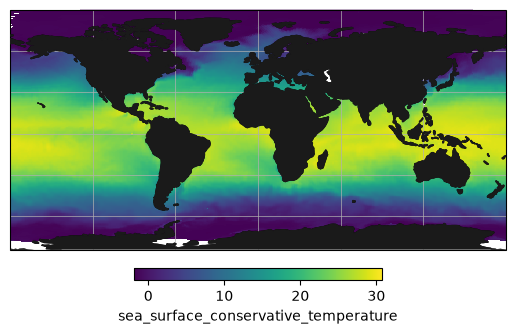

In [20]:
# -- Plot example sea surface temperature (°C) -- #
nemo["gridT/tos_con"].isel(time_counter=0).geoplot()

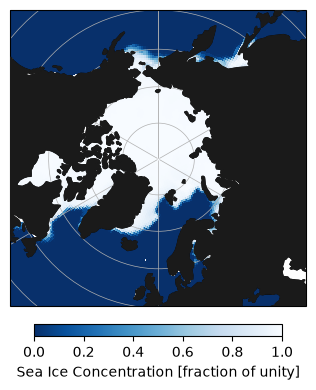

In [21]:
# -- Plot example sea ice concentration in the Northern Hemisphere -- #
proj = ccrs.NorthPolarStereo()

(nemo["gridT/siconc"]
 .isel(time_counter=0)
 .geoplot(projection=proj,
          vmin=0, vmax=1,
          extent=(-180, 180, 50, 90),
          cmap='Blues_r',
          clabel_kwargs={'label': 'Sea Ice Concentration [fraction of unity]'}
          )
 )

#### **1.5.1 Indexing**

---

* Alongside the more familiar `.sel()` and `.isel()` label based selection methods, the `.sel_like()` method can be used to index a `NEMODataArray` according to the dimension index labels of another `NEMODataArray` or `xarray.DataArray` as follows:

In [22]:
nda = nemo["gridT/thetao_con"].sel(i=slice(1, 90), k=20)

nemo["gridT/thetao_con"].sel_like(nda)

<NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>

<xarray.DataArray 'thetao_con' (time_counter: 604, j: 331, i: 90)> Size: 72MB
dask.array<getitem, shape=(604, 331, 90), dtype=float32, chunksize=(1, 331, 90), chunktype=numpy.ndarray>
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
    time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
  * j              (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
  * i              (i) int64 720B 1 2 3 4 5 6 7 8 9 ... 83 84 85 86 87 88 89 90
    glamt          (j, i) float64 238kB dask.array<chunksize=(331, 90), meta=np.ndarray>
    gphit          (j, i) float64 238kB dask.array<chunksize=(331, 90), meta=np.ndarray>
    deptht         float32 4B dask.array<chunksize=(), meta=np.ndarray>
    k              int64 8B 20
Attributes:
    standard_name:       sea_water_conservative_temperature
    long_name:           sea_water_conservative_temperature
    units:               degC
    online_operation:    average
    interval_operation:  1 month
    interval_write:      1 month
    cell_methods:        time: mean

* We can also use the `add_geoindex()` method of our `NEMODataTree` to enable indexing of a NEMO model variables with geographical coordinates:

**Note that the `.dataset` property must be used to access the `xarray.Dataset` view of the NEMO model grid node**

In [23]:
nemo_geo = nemo.add_geoindex(grid="gridT")

nemo_geo["gridT"].dataset.sel(gphit=60, glamt=-40, method="nearest")

<xarray.Dataset> Size: 733kB
Dimensions:        (time_counter: 604, k: 75, ncatice: 5)
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
    time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
  * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
    deptht         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
  * ncatice        (ncatice) float32 20B 1.0 2.0 3.0 4.0 5.0
    j              int64 8B 275
    i              int64 8B 249
    gphit          float64 8B dask.array<chunksize=(), meta=np.ndarray>
    glamt          float64 8B dask.array<chunksize=(), meta=np.ndarray>
Data variables: (12/65)
    albedo         (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    e1t            float64 8B dask.array<chunksize=(), meta=np.ndarray>
    e2t            float64 8B dask.array<chunksize=(), meta=np.ndarray>
    e3t            (time_counter, k) float32 181kB dask.array<chunksize=(1, 25), meta=np.ndarray>
    fsitherm       (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    friver         (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    ...             ...
    sivelo         (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    tossq_con      (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    zos            (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    tos_con        (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    tnpeo          (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
    zossq          (time_counter) float32 2kB dask.array<chunksize=(1,), meta=np.ndarray>
Attributes: (12/29)
    Conventions:                 CF-1.6
    title:                       National Oceanography Centre Near-Present Da...
    description:                 NOC Near-Present Day monthly mean global oce...
    dataset_type:                model
    product_type:                timeseries
    product_version:             1.0
    ...                          ...
    ocean_component:             NEMO v4.2.2
    sea_ice_component:           SI3 v4.0
    biogeochemistry_component:   None
    atmospheric_component:       None
    atmospheric_forcing:         ERA5 v1
    variant:                     r1i1c1f1

#### **1.5.2 Clipping & Masking**

---

* We often want to perform a calculation using only NEMO grid points within a specific region.

* To clip a `NEMODataArray` to include only data within a geographical bounding box, we can use the `clip()` method.


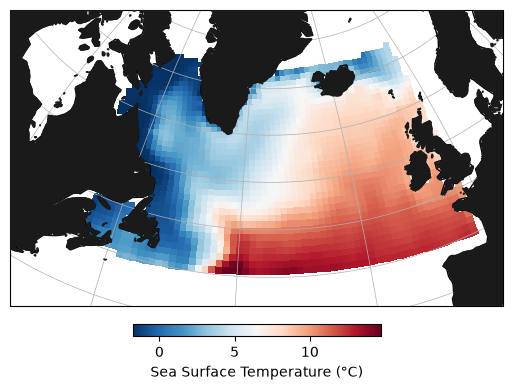

In [24]:
# Define subpolar North Atlantic boundary box for analysis:
bbox_spna = (-68, -2, 45, 67)  # (-68°E, -2°E, 45°N, 67°N)

# Plot the sea surface temperature (°C) in the subpolar North Atlantic region:
(nemo["gridT/tos_con"]
 .clip(bbox_spna)
 .isel(time_counter=0)
 .geoplot(projection=ccrs.Orthographic(central_longitude=-35, central_latitude=50),
          extent=(-75, 0, 42, 70), # (-75°E, -0°E, 42°N, 70°N)
          cmap='RdBu_r',
          clabel_kwargs={'label': 'Sea Surface Temperature (°C)'}
          )
 )

* To define a regional mask using the geographical coordinates of a closed polygon, we can use the `mask_with_polygon()` method.

* In this example, we use the IHO World Seas v3 Labrador Sea polygon to generate the longitude and latitude coordinates of the closed polygon to mask.

In [25]:
# Open IHO World Seas v3 polygons from JASMIN Object Store as Pandas DataFrame:
filepaths = ncb.examples.get_filepaths("IHO")

df_IHO_World_Seas = pd.read_parquet(filepaths['IHO_World_Seas_v3_polygons.parquet'])


# Define IHO World Seas Labrador Sea polygon:
lon_poly = df_IHO_World_Seas[df_IHO_World_Seas['Name'] == 'Labrador Sea']['Longitudes'].item()[0]
lat_poly = df_IHO_World_Seas[df_IHO_World_Seas['Name'] == 'Labrador Sea']['Latitudes'].item()[0]

# Define boolean mask for Labrador Sea:
LSea_mask = nemo.mask_with_polygon(grid='gridT', lon_poly=lon_poly, lat_poly=lat_poly)

LSea_mask

<xarray.DataArray (j: 331, i: 360)> Size: 119kB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(331, 360))
Dimensions without coordinates: j, i

* Next, let's create a plot applying our regional mask to a given `NEMODataArray` variable using the `apply_mask()` method.

**Note that using `apply_mask()` is preferred over `where()` since this automatically applies the appropriate land-sea mask in addition to our custom mask**

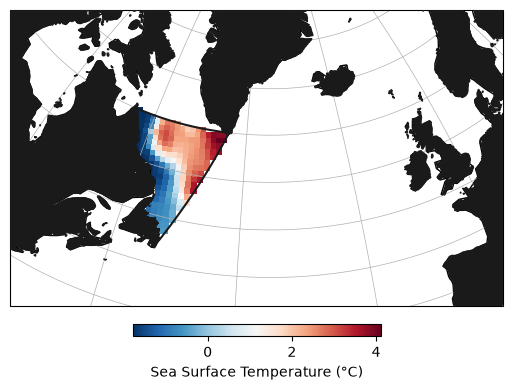

In [26]:
# Plotting Labrador Sea sub-domain sea surface temperature:
(nemo['gridT/tos_con']
 .isel(time_counter=0)
 .apply_mask(LSea_mask)
 .geoplot(projection=ccrs.Orthographic(central_longitude=-35, central_latitude=50),
          extent=(-75, 0, 42, 70), # (-75°E, -0°E, 42°N, 70°N)
          cmap='RdBu_r',
          clabel_kwargs={'label': 'Sea Surface Temperature (°C)'}
          )
 )

# Add IHO World Seas Labrador Sea polygon:
plt.plot(lon_poly, lat_poly, transform=ccrs.PlateCarree(), color='0.1', linewidth=1.5)

* For more details on clipping grids and domains within a `NEMODataTree` see the following section of the [**How To... Guide**](https://noc-msm.github.io/nemo_cookbook/howto/#clip-a-nemo-model-grid).

#### **1.5.3 Grid Operators**

---

* Grid operators are the foundational set of finite difference operators defined on the NEMO model grid.

* For example, the difference operator $\delta_{i} [q]$ is defined by...

$$\delta_{i} [q] = q(i + 1/2) - q(i - 1/2)$$

* ...and the integral operator acting along the $i$-dimension is given by:

$$\sum_{i=i_{1}}^{i_{2}} q_{i, j, k} \ e_{1 i, j, k}$$

* For a complete list of grid operators implemented in NEMO Cookbook, see the following sections of the [**How To... Guide**](https://noc-msm.github.io/nemo_cookbook/howto/#calculate-horizontal-derivatives).

* Here, we will focus on the `integral()` method, which can be used to integrate a variable `var` along one or more dimensions `dims` of a given NEMO model grid `grid`.



* As an example, let's compute the total March mixed layer volume in the subpolar North Atlantic...

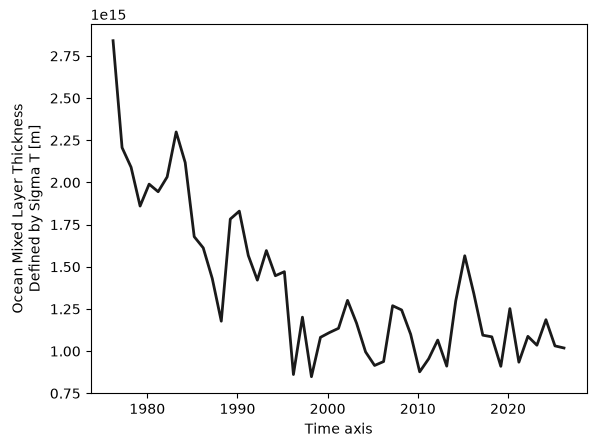

In [27]:
(nemo["gridT/mlotst"]
 # Select only March months:
 .sel(time_counter=nemo["gridT/time_counter"].dt.month == 3)
 # Clip to the SPNA bbox (-68°E, -2°E, 45°N, 67°N):
 .clip(bbox_spna)
 # Calculate area integral of mixed layer depth (m -> m³) in the SPNA:
 .integral(dims=["i", "j"])
 # Plot March mixed layer volume in the SPNA (m³):
 .plot(linewidth=2, color='0.1')
 )

* We can also use the `.integral()` method to calculate cumulative integrals along one or more dimensions of a given NEMO model grid.

* For more details on cumulative integration see the following section of the [**How To... Guide**](https://noc-msm.github.io/nemo_cookbook/howto/#calculate-cumulative-integrals).

#### **1.5.4 Grid Transformations**
---

* Given that scalar and vector NEMO output variables are not co-located on the model grid, we often need to transform a variable defined on a given NEMO horizontal grid to a neighbouring grid via linear interpolation.

* For example, we can transform the seawater potential temperature `thetao_con` defined on scalar **T**-points to neighbouring **V**-points in a NEMO model parent domain using the `.interp_to()` method:

In [28]:
nemo['gridT/thetao_con'].interp_to(to='V')

<NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridV', Grid Type: 'V')>

<xarray.DataArray 'thetao_con' (time_counter: 604, k: 75, j: 331, i: 360)> Size: 43GB
dask.array<where, shape=(604, 75, 331, 360), dtype=float64, chunksize=(1, 25, 331, 360), chunktype=numpy.ndarray>
Coordinates:
  * time_counter  (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... 2...
  * k             (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
    depthv        (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
  * j             (j) float64 3kB 1.5 2.5 3.5 4.5 ... 328.5 329.5 330.5 331.5
  * i             (i) int64 3kB 1 2 3 4 5 6 7 8 ... 354 355 356 357 358 359 360
    glamv         (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    gphiv         (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Attributes:
    units:               degC
    online_operation:    average
    interval_operation:  1 month
    interval_write:      1 month
    cell_methods:        time: mean

**Note that the original T-grid coordinate variables have been replaced by those of the V-grid onto which the conservative temperature field has been linearly interpolated.**

* We can also transform a variable defined on a given NEMO model vertical grid to a new vertical grid using conservative interpolation via the `.transform_vertical_grid()` method.

* For more details on vertical grid transformations see the following section of the [**How To... Guide**](https://noc-msm.github.io/nemo_cookbook/howto/#interpolate-variable-to-a-neighbouring-horizontal-grid).

#### **1.5.5 Statistics**
---

* We often want to calculate grid-aware statistics, such as area-weighted averages, using NEMO model outputs.

* Here, we leverage method chaining and the `weighted_mean()` method to calculate the horizontal grid cell area-weighted average sea surface temperature in the Labrador Sea:

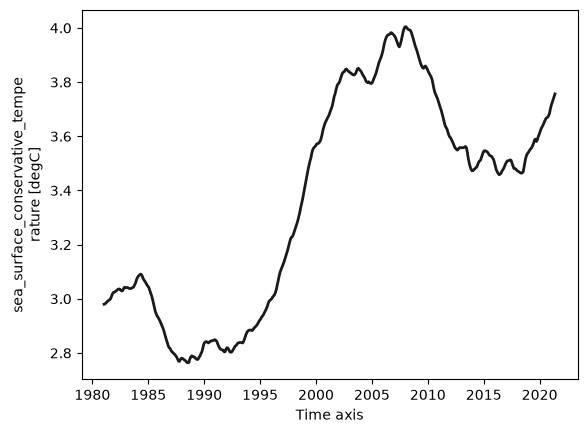

In [29]:
# Calculate the area weighted-mean sea surface temperature in the Labrador Sea:
tos_LSea_wmean = nemo["gridT/tos_con"].apply_mask(LSea_mask).weighted_mean(dims=["i", "j"])

(tos_LSea_wmean
 .rolling(time_counter=120, center=True) # -> 120-month rolling average.
 .mean()
 .plot(linewidth=2, color='0.1')
)

* We can also calculate aggregated statistics of a variable binned according to the values of one or more variables using the `NEMODataTree.binned_statistic()` method.

* For more details on statistical methods see the following section of the [**How To... Guide**](https://noc-msm.github.io/nemo_cookbook/howto/#calculate-statistics-for-a-region-masked-using-a-polygon).

#### **1.5.6 Extracting Hydrographic Sections**
---

* Finally, we often want to compute volume, heat and freshwater transports across trans-basin hydrographic sections in order to compare NEMO models with available observations.

* In this example, we use the `extract_zonal_section()` method to extract an approximately zonal section at the latitude of the RAPID-MOCHA array usinf our `NEMODataTree`.

* The resulting hydrographic section will be defined on NEMO V-grid points at the constant `j`-coordinate whose average latitude is closest to 27.5°N.

In [30]:
# Extract the RAPID-MOCHA array, including conservative temperature and absolute salinity interpolated onto V-points:
ds_rapid = nemo.extract_zonal_section(lat=26.5,
                                      lon_min=-82.0,
                                      lon_max=-10.0,
                                      u_vars=None,
                                      scalar_vars=['thetao_con', 'so_abs'],
                                      dom='.'
                                      )

ds_rapid

<xarray.Dataset> Size: 105MB
Dimensions:        (time_counter: 604, bdy: 72, k: 75)
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 5kB 1976-01-16T12:00:00 ... ...
    time_centered  (time_counter) datetime64[ns] 5kB dask.array<chunksize=(1,), meta=np.ndarray>
  * i              (bdy) int64 576B 206 207 208 209 210 ... 273 274 275 276 277
    gphib          (bdy) float64 576B dask.array<chunksize=(72,), meta=np.ndarray>
    glamb          (bdy) float64 576B dask.array<chunksize=(72,), meta=np.ndarray>
  * k              (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
    depthb         (k) float32 300B dask.array<chunksize=(75,), meta=np.ndarray>
    j              float64 8B 229.5
Dimensions without coordinates: bdy
Data variables: (12/15)
    hfy            (time_counter, bdy) float32 174kB dask.array<chunksize=(1, 72), meta=np.ndarray>
    e1b            (bdy) float64 576B dask.array<chunksize=(72,), meta=np.ndarray>
    e2b            (bdy) float64 576B dask.array<chunksize=(72,), meta=np.ndarray>
    e3b            (time_counter, k, bdy) float32 13MB dask.array<chunksize=(1, 25, 72), meta=np.ndarray>
    tauvo          (time_counter, bdy) float32 174kB dask.array<chunksize=(1, 72), meta=np.ndarray>
    vo_eiv         (time_counter, k, bdy) float32 13MB dask.array<chunksize=(1, 25, 72), meta=np.ndarray>
    ...             ...
    vmo            (time_counter, k, bdy) float32 13MB dask.array<chunksize=(1, 25, 72), meta=np.ndarray>
    somesatr       (time_counter, bdy) float32 174kB dask.array<chunksize=(1, 72), meta=np.ndarray>
    thetao_con     (time_counter, k, bdy) float64 26MB dask.array<chunksize=(1, 25, 72), meta=np.ndarray>
    so_abs         (time_counter, k, bdy) float64 26MB dask.array<chunksize=(1, 25, 72), meta=np.ndarray>
    i_bdy          (bdy) int64 576B 206 207 208 209 210 ... 273 274 275 276 277
    j_bdy          (bdy) float64 576B 229.5 229.5 229.5 ... 229.5 229.5 229.5
Attributes: (12/29)
    Conventions:                 CF-1.6
    title:                       National Oceanography Centre Near-Present Da...
    description:                 NOC Near-Present Day monthly mean global oce...
    dataset_type:                model
    product_type:                timeseries
    product_version:             1.0
    ...                          ...
    ocean_component:             NEMO v4.2.2
    sea_ice_component:           SI3 v4.0
    biogeochemistry_component:   None
    atmospheric_component:       None
    atmospheric_forcing:         ERA5 v1
    variant:                     r1i1c1f1

**Taking a closer look at our hydrographic section dataset, we can see it is structured analogously to a NEMO model grid node within our `NEMODataTree`:**

* Inherited NEMO Grid Dimension: `k`

* New Along-Boundary Grid Dimension: `bdy`, such that `i_bdy(bdy)`, `j_bdy(bdy)`

* Geographical Coordinates: `glamb` (longitude), `gphib` (latitude).

* Horizontal Grid Scale Factors: `e1b`, `e2b`

* Vertical Grid Scale Factors: `e3b`

* Land-Sea Masks: `bmask`, `bmaskutil`

(6000.0, 0.0)

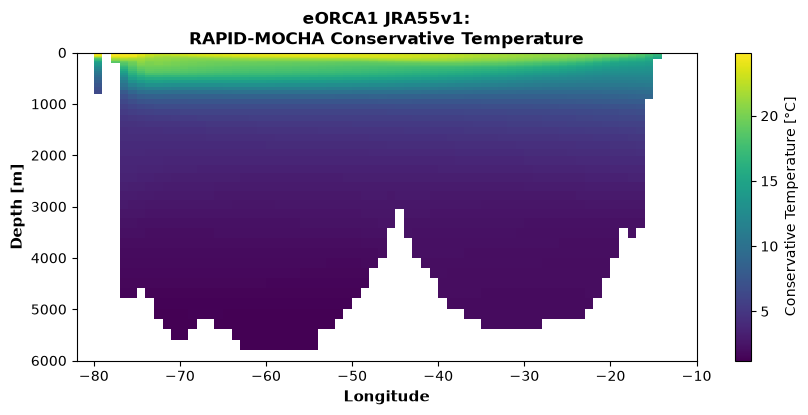

In [33]:
# -- Plot the time-mean conservative temperature along the RAPID-MOCHA section -- #
plt.figure(figsize=(10, 4))

# Plot time-mean conservative temperature across RAPID-MOCHA section:
(ds_rapid['thetao_con']
 .sel(time_counter=slice("2026-01", "2026-04"))
 .mean(dim='time_counter')
 .plot(x='glamb', y='depthb', yincrease=False, cbar_kwargs={"label": "Conservative Temperature [°C]"})
 )

# Axes labels:
plt.title("eORCA1 JRA55v1:\nRAPID-MOCHA Conservative Temperature", fontdict={'size':12, 'weight':'bold'})
plt.xlabel("Longitude", fontdict={'size':11, 'weight':'bold'})
plt.ylabel("Depth [m]", fontdict={'size':11, 'weight':'bold'})
plt.ylim([6000, 0])